# Mixture Deep SVDD-Augmented XGBoost — Binary IDS Gate
**Pipeline:** RobustScaler → K-Means Elbow → Mixture Deep SVDD (K spheres) → concat [features | K sphere distances | d_min] → XGBoost (binary)

SVDD chỉ đóng vai trò **feature encoder**: khoảng cách tới từng benign sphere (K feature) cộng d_min (khoảng cách nhỏ nhất) được nối vào 78 feature gốc. XGBoost là điểm quyết định duy nhất — không có ngưỡng SVDD riêng, không OR-Fusion.

## CELL 1 — Imports & Config

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    f1_score, accuracy_score, precision_score,
    recall_score, confusion_matrix, classification_report,
    roc_auc_score
)
import xgboost as xgb
import joblib
import time
import os


#  DOI DATASET
#
#   v0 Slowloris :    DATA_PATH = "../binary_split_zeroshot_dataset/"
#                     ZEROSHOT_FILE  = "DoS attacks-Slowloris.csv"
#                     ZEROSHOT_LABEL = "DoS Slowloris"
#                     ARTIFACT_SUFFIX = "_v0_slowloris"
#   v1 Infilteration: DATA_PATH = "../binary_split_dataset_z_Infilteration/"
#                     ZEROSHOT_FILE  = "Infilteration.csv"
#                     ZEROSHOT_LABEL = "Infilteration"
#                     ARTIFACT_SUFFIX = "_v1_infilteration"


DATA_PATH      = "../binary_split_dataset_z_Infilteration/"
ZEROSHOT_FILE  = "Infilteration.csv"
ZEROSHOT_LABEL = "Infilteration"
ARTIFACT_SUFFIX = "_v1_infilteration"

# Thu muc luu output — tao moi lan chay neu chua co
IMAGES_DIR = "images"
CKPT_DIR   = "checkpoints"
os.makedirs(IMAGES_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

# Paths cho model artifacts (tat ca nam trong checkpoints/)
SVDD_MODEL_DIR  = os.path.join(CKPT_DIR, f"svdd_model{ARTIFACT_SUFFIX}")
XGB_PATH        = os.path.join(CKPT_DIR, f"xgb_svdd_model{ARTIFACT_SUFFIX}.pkl")
SCALER_PATH     = os.path.join(CKPT_DIR, f"scaler_svdd{ARTIFACT_SUFFIX}.pkl")
KMEANS_PATH     = os.path.join(CKPT_DIR, f"kmeans_assign{ARTIFACT_SUFFIX}.pkl")
KMEANS_SUB_PATH = os.path.join(CKPT_DIR, f"kmeans_sub{ARTIFACT_SUFFIX}.pkl")


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED   = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

FEATURES = [
    'Dst Port', 'Protocol', 'Flow Duration', 'Tot Fwd Pkts',
    'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
    'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max',
    'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s',
    'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
    'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
    'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min',
    'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags',
    'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s',
    'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var',
    'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt',
    'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt',
    'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg',
    'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg',
    'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg', 'Subflow Fwd Pkts', 'Subflow Fwd Byts',
    'Subflow Bwd Pkts', 'Subflow Bwd Byts', 'Init Fwd Win Byts',
    'Init Bwd Win Byts', 'Fwd Act Data Pkts', 'Fwd Seg Size Min',
    'Active Mean', 'Active Std', 'Active Max', 'Active Min',
    'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min'
]

DTYPE_DICT = {feat: 'float32' for feat in FEATURES}
DTYPE_DICT['Label'] = 'int8'

print(f"Device         : {DEVICE}")
print(f"Dataset        : {DATA_PATH}")
print(f"Zero-shot file : {ZEROSHOT_FILE}")
print(f"Artifact suffix: {ARTIFACT_SUFFIX}")
print(f"Num features   : {len(FEATURES)}")
print(f"Images dir     : {IMAGES_DIR}/")
print(f"Checkpoints dir: {CKPT_DIR}/")

Device         : cuda
Dataset        : ../binary_split_dataset_z_Infilteration/
Zero-shot file : Infilteration.csv
Artifact suffix: _v1_infilteration
Num features   : 78
Images dir     : images/
Checkpoints dir: checkpoints/


## CELL 2 — Load Data

In [19]:
print("Loading data...")

train_svdd_df = pd.read_csv(
    DATA_PATH + 'train_isolation_benign.csv',
    usecols=FEATURES + ['Label'], dtype=DTYPE_DICT
)

train_xgb_df = pd.read_csv(
    DATA_PATH + 'train_xgboost_binary.csv',
    usecols=FEATURES + ['Label'], dtype=DTYPE_DICT
)
val_df  = pd.read_csv(DATA_PATH + 'val_binary.csv',  usecols=FEATURES + ['Label'], dtype=DTYPE_DICT)
test_df = pd.read_csv(DATA_PATH + 'test_binary.csv', usecols=FEATURES + ['Label'], dtype=DTYPE_DICT)

# Zero-shot file có thể có Timestamp string → dùng usecols để bỏ qua
zeroshot_df = pd.read_csv(
    DATA_PATH + ZEROSHOT_FILE,
    usecols=FEATURES + ['Label'], dtype=DTYPE_DICT
)

print(f"SVDD train (benign only)  : {len(train_svdd_df):,}")
print(f"XGB  train (binary)       : {len(train_xgb_df):,}  | attack={train_xgb_df['Label'].sum():,}")
print(f"Val                       : {len(val_df):,}")
print(f"Test                      : {len(test_df):,}")
print(f"Zero-shot ({ZEROSHOT_LABEL}): {len(zeroshot_df):,}")

Loading data...
SVDD train (benign only)  : 1,134,432
XGB  train (binary)       : 1,418,040  | attack=283,608
Val                       : 303,855
Test                      : 303,900
Zero-shot (Infilteration): 161,934


## CELL 3 — RobustScaler

In [20]:
X_svdd_train = train_svdd_df[FEATURES].values

X_xgb_train = train_xgb_df[FEATURES].values
y_xgb_train = train_xgb_df['Label'].values

X_val  = val_df[FEATURES].values;  y_val  = val_df['Label'].values
X_test = test_df[FEATURES].values; y_test = test_df['Label'].values

# Zero-shot: replace inf/NaN trước khi scale
X_zeroshot_raw = zeroshot_df[FEATURES].values.astype('float32')
X_zeroshot_raw = np.where(np.isfinite(X_zeroshot_raw), X_zeroshot_raw, 0.0)
y_zeroshot = np.ones(len(zeroshot_df), dtype=int)  # All attack

scaler = RobustScaler()
X_svdd_train_s = scaler.fit_transform(X_svdd_train)
X_xgb_train_s  = scaler.transform(X_xgb_train)
X_val_s        = scaler.transform(X_val)
X_test_s       = scaler.transform(X_test)
X_zeroshot_s   = scaler.transform(X_zeroshot_raw)

CLIP_VAL = 20.0
X_svdd_train_s = np.clip(X_svdd_train_s, -CLIP_VAL, CLIP_VAL)
X_xgb_train_s  = np.clip(X_xgb_train_s,  -CLIP_VAL, CLIP_VAL)
X_val_s        = np.clip(X_val_s,         -CLIP_VAL, CLIP_VAL)
X_test_s       = np.clip(X_test_s,        -CLIP_VAL, CLIP_VAL)
X_zeroshot_s   = np.clip(X_zeroshot_s,    -CLIP_VAL, CLIP_VAL)

joblib.dump(scaler, SCALER_PATH)
print("RobustScaler fit on benign train — done.")
print(f"Scaler saved: {SCALER_PATH}")
print(f"Clip [-{CLIP_VAL}, {CLIP_VAL}] applied to all splits.")

RobustScaler fit on benign train — done.
Scaler saved: checkpoints\scaler_svdd_v1_infilteration.pkl
Clip [-20.0, 20.0] applied to all splits.


## CELL 4 — K-Means Elbow Curve (chọn K cho Mixture SVDD)

Running K-Means elbow...
  K=2  inertia=161939856.00  silhouette=0.3265
  K=3  inertia=117242464.00  silhouette=0.3837
  K=4  inertia=100559248.00  silhouette=0.3260
  K=5  inertia=87945376.00  silhouette=0.3423
  K=6  inertia=75811272.00  silhouette=0.3728
  K=7  inertia=68955080.00  silhouette=0.3914
  K=8  inertia=60874768.00  silhouette=0.4091
  K=9  inertia=55494488.00  silhouette=0.3905
  K=10  inertia=50665028.00  silhouette=0.4192


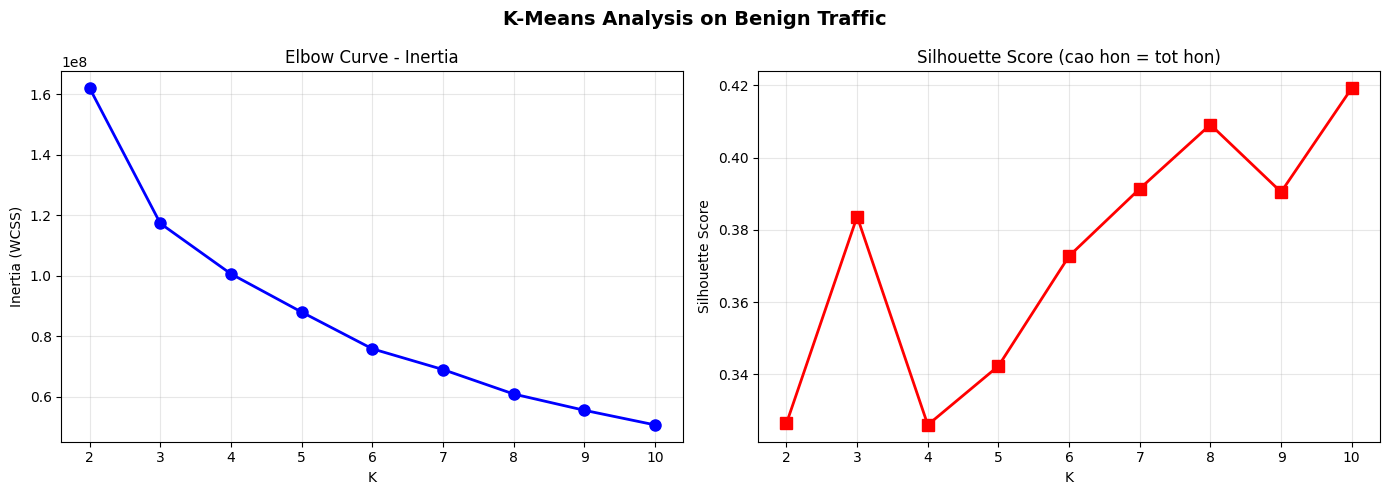

Saved: images\kmeans_elbow.png


In [21]:
# Subsample de elbow chay nhanh (100K la du)
MAX_ELBOW = 100_000
idx = np.random.choice(len(X_svdd_train_s), min(MAX_ELBOW, len(X_svdd_train_s)), replace=False)
X_elbow = X_svdd_train_s[idx]

K_range = range(2, 11)
inertias, silhouette_scores = [], []

from sklearn.metrics import silhouette_score

print("Running K-Means elbow...")
for k in K_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=5, max_iter=200)
    labels = km.fit_predict(X_elbow)
    inertias.append(km.inertia_)
    # Silhouette hoi cham -> sample them
    sil_idx = np.random.choice(len(X_elbow), min(10_000, len(X_elbow)), replace=False)
    sil = silhouette_score(X_elbow[sil_idx], labels[sil_idx])
    silhouette_scores.append(sil)
    print(f"  K={k}  inertia={km.inertia_:.2f}  silhouette={sil:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('K'); axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Curve - Inertia')
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(K_range), silhouette_scores, 'rs-', linewidth=2, markersize=8)
axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score (cao hon = tot hon)')
axes[1].grid(True, alpha=0.3)

plt.suptitle('K-Means Analysis on Benign Traffic', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'kmeans_elbow.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {os.path.join(IMAGES_DIR, 'kmeans_elbow.png')}")

## CELL 5 — Visualize Benign Sub-clusters (PCA 2D)
> Chỉ để quan sát — PCA không được dùng cho training SVDD

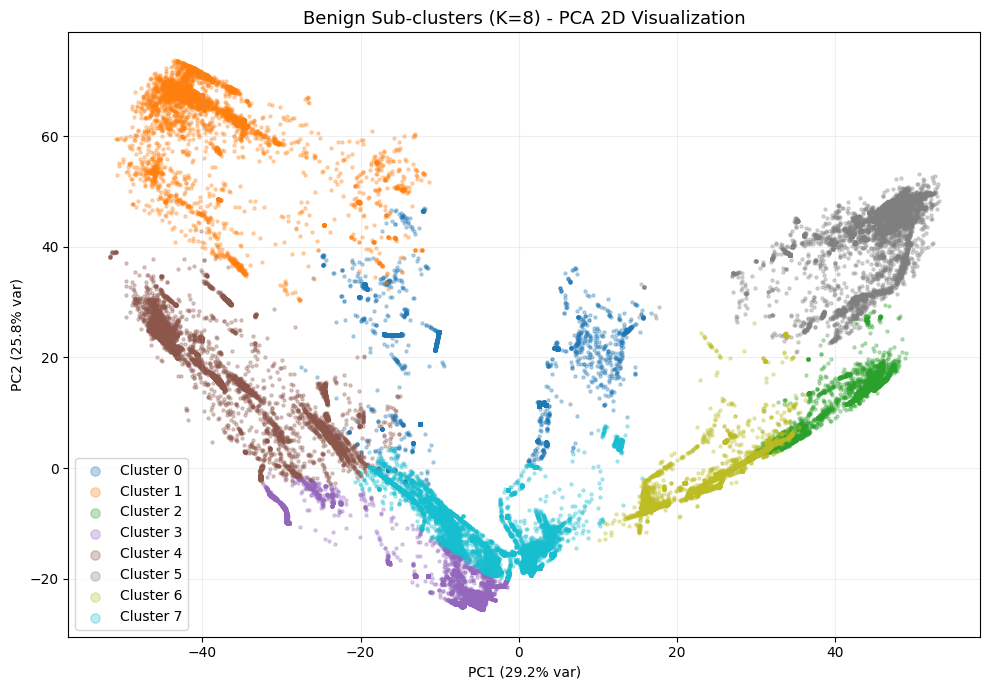

In [22]:
K_CHOSEN = 8  # <- Dieu chinh sau khi xem elbow curve

from sklearn.decomposition import PCA

km_final = KMeans(n_clusters=K_CHOSEN, random_state=SEED, n_init=10)
cluster_labels = km_final.fit_predict(X_elbow)

pca_vis = PCA(n_components=2, random_state=SEED)
X_2d = pca_vis.fit_transform(X_elbow)

fig, ax = plt.subplots(figsize=(10, 7))
palette = plt.cm.tab10(np.linspace(0, 1, K_CHOSEN))
cluster_names = []

for k in range(K_CHOSEN):
    mask = cluster_labels == k
    label = cluster_names[k] if k < len(cluster_names) else f'Cluster {k}'
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
               c=[palette[k]], label=label, alpha=0.3, s=5)

ax.set_title(f'Benign Sub-clusters (K={K_CHOSEN}) - PCA 2D Visualization', fontsize=13)
ax.set_xlabel(f'PC1 ({pca_vis.explained_variance_ratio_[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({pca_vis.explained_variance_ratio_[1]*100:.1f}% var)')
ax.legend(markerscale=3)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'benign_clusters_pca.png'), dpi=150, bbox_inches='tight')
plt.show()

## CELL 6 — Deep SVDD Model Definition

In [23]:
class SVDDEncoder(nn.Module):
    """
    MLP Encoder: 84 → 256 → 128 → 64
    Output L2-normalized embedding trên unit sphere.
    Dùng LayerNorm thay BatchNorm để tránh lỗi khi batch_size=1.
    Không dùng bias ở layer cuối (chuẩn Deep SVDD).
    """
    def __init__(self, input_dim=78, embed_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, embed_dim, bias=False)  # No bias — Deep SVDD rule
        )

    def forward(self, x):
        z = self.net(x)
        return nn.functional.normalize(z, dim=1)  # L2 normalize → unit sphere


class MixtureSVDD:
    """
    K independent SVDD spheres, mỗi sphere bao quanh 1 benign sub-cluster.
    Inference: d_min = min distance đến K centers.
    """
    def __init__(self, K=5, input_dim=78, embed_dim=64,
                 nu=0.1, lr=1e-3, epochs=30, batch_size=2048, device='cpu'):
        self.K          = K
        self.nu         = nu        # Fraction of outliers tolerated (0.05–0.15)
        self.lr         = lr
        self.epochs     = epochs
        self.batch_size = batch_size
        self.device     = device
        self.input_dim  = input_dim
        self.embed_dim  = embed_dim

        # K encoders + K centers + K radii
        self.encoders = [SVDDEncoder(input_dim, embed_dim).to(device) for _ in range(K)]
        self.centers  = [None] * K   # Sẽ được khởi tạo lúc train
        self.radii    = [None] * K

    def _init_center(self, encoder, loader):
        """Khởi tạo center = trung bình embedding của toàn bộ data."""
        encoder.eval()
        zs = []
        with torch.no_grad():
            for (xb,) in loader:
                xb = xb.to(self.device)
                zs.append(encoder(xb))
        c = torch.cat(zs).mean(0)
        # Tránh center bằng 0 (collapse)
        c[(c.abs() < 1e-6)] = 1e-6
        return c.detach()

    def fit(self, X_clusters):
        """
        X_clusters: list gồm K arrays, mỗi array là samples của 1 sub-cluster.
        """
        for k in range(self.K):
            print(f"\n── Training SVDD sphere {k+1}/{self.K}  "
                  f"(n={len(X_clusters[k]):,}) ──")
            X_k = torch.tensor(X_clusters[k], dtype=torch.float32)
            loader = DataLoader(TensorDataset(X_k),
                                batch_size=self.batch_size, shuffle=True,
                                drop_last=False)  

            encoder = self.encoders[k]
            optimizer = optim.Adam(encoder.parameters(), lr=self.lr, weight_decay=1e-5)
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.epochs)

            # Init center
            # Init center dùng loader riêng KHÔNG drop_last
            init_loader = DataLoader(TensorDataset(X_k),
                                     batch_size=self.batch_size, shuffle=False,
                                     drop_last=False)
            c = self._init_center(encoder, init_loader)
            self.centers[k] = c

            best_loss = float('inf')
            for epoch in range(self.epochs):
                encoder.train()
                epoch_loss = 0.0
                for (xb,) in loader:
                    xb = xb.to(self.device)
                    z = encoder(xb)
                    # Soft-boundary Deep SVDD loss
                    dist = ((z - c) ** 2).sum(dim=1)
                    loss = dist.mean() + (1 / self.nu) * torch.relu(dist - dist.quantile(1 - self.nu)).mean()
                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()
                    epoch_loss += loss.item()
                scheduler.step()
                avg = epoch_loss / len(loader)
                if avg < best_loss:
                    best_loss = avg
                if (epoch + 1) % 5 == 0:
                    print(f"  Epoch {epoch+1:3d}/{self.epochs}  loss={avg:.6f}")

            # Tính radius = quantile (1-nu) của distances trên training data
            # Dùng loader riêng KHÔNG drop_last để tính đủ toàn bộ samples
            radius_loader = DataLoader(TensorDataset(X_k),
                                       batch_size=self.batch_size, shuffle=False,
                                       drop_last=False)
            encoder.eval()
            dists = []
            with torch.no_grad():
                for (xb,) in radius_loader:
                    xb = xb.to(self.device)
                    z = encoder(xb)
                    dists.append(((z - c) ** 2).sum(dim=1))
            all_dists = torch.cat(dists)
            self.radii[k] = torch.quantile(all_dists, 1 - self.nu).item()
            print(f"  Radius R_{k} = {self.radii[k]:.6f}")

    def all_sphere_distances(self, X_np):
        """
        Trả về ma trận [n_samples, K]: khoảng cách bình phương đến TỪNG center.
        Dùng làm K feature bổ sung cho XGBoost (thay vì chỉ 1 d_min tổng hợp).
        """
        X_t = torch.tensor(X_np, dtype=torch.float32)
        loader = DataLoader(TensorDataset(X_t), batch_size=4096, shuffle=False)
        all_dists = []
        for k in range(self.K):
            self.encoders[k].eval()
            c = self.centers[k]
            dists_k = []
            with torch.no_grad():
                for (xb,) in loader:
                    xb = xb.to(self.device)
                    z = self.encoders[k](xb)
                    dists_k.append(((z - c) ** 2).sum(dim=1).cpu().numpy())
            all_dists.append(np.concatenate(dists_k))
        return np.stack(all_dists, axis=1)  # [n_samples, K]

    def decision_scores(self, X_np):
        """
        Trả về d_min: khoảng cách nhỏ nhất đến K centers.
        Score cao → anomaly, score thấp → benign.
        """
        return self.all_sphere_distances(X_np).min(axis=1)

    def predict(self, X_np):
        """Binary prediction dựa trên R (radius) của sphere gần nhất."""
        X_t = torch.tensor(X_np, dtype=torch.float32)
        loader = DataLoader(TensorDataset(X_t), batch_size=4096, shuffle=False)
        pred_flags = np.ones(len(X_np), dtype=int)  # Default = anomaly
        for k in range(self.K):
            self.encoders[k].eval()
            c = self.centers[k]
            dists_k = []
            with torch.no_grad():
                for (xb,) in loader:
                    xb = xb.to(self.device)
                    z = self.encoders[k](xb)
                    dists_k.append(((z - c) ** 2).sum(dim=1).cpu().numpy())
            d = np.concatenate(dists_k)
            # Nếu nằm trong sphere k → benign
            pred_flags[d <= self.radii[k]] = 0
        return pred_flags

    def save(self, path='../svdd_model'):
        os.makedirs(path, exist_ok=True)
        for k, enc in enumerate(self.encoders):
            torch.save(enc.state_dict(), f'{path}/encoder_{k}.pt')
        np.save(f'{path}/centers.npy', [c.cpu().numpy() for c in self.centers])
        np.save(f'{path}/radii.npy', self.radii)
        print(f"SVDD saved to '{path}/'")

    def load(self, path='../svdd_model'):
        centers_np = np.load(f'{path}/centers.npy', allow_pickle=True)
        self.radii  = list(np.load(f'{path}/radii.npy', allow_pickle=True))
        for k, enc in enumerate(self.encoders):
            enc.load_state_dict(torch.load(f'{path}/encoder_{k}.pt', map_location=self.device))
            self.centers[k] = torch.tensor(centers_np[k], dtype=torch.float32).to(self.device)
        print(f"SVDD loaded from '{path}/'")

print("MixtureSVDD class defined.")

MixtureSVDD class defined.


## CELL 7 — Phân chia Benign thành K sub-clusters (dùng K-Means)

In [24]:
K_CHOSEN   = 8    # Ket qua elbow curve
K_SPLIT    = 3    # Chia cluster lon nhat thanh 3 cum con
MIN_SIZE   = 2048 # Loai bo cluster nho hon batch_size (tranh loi training)

if os.path.exists(KMEANS_PATH) and os.path.exists(KMEANS_SUB_PATH):
    print(f"[Checkpoint] Found {KMEANS_PATH} and {KMEANS_SUB_PATH} - loading, skipping K-Means fit...")
    km_assign = joblib.load(KMEANS_PATH)
    km_sub    = joblib.load(KMEANS_SUB_PATH)

    cluster_assign = km_assign.predict(X_svdd_train_s)
    raw_clusters = {k: X_svdd_train_s[cluster_assign == k] for k in range(K_CHOSEN)}
    largest_k = max(raw_clusters, key=lambda k: len(raw_clusters[k]))
    X_largest = raw_clusters[largest_k]
    sub_assign = km_sub.predict(X_largest)
    sub_clusters = {j: X_largest[sub_assign == j] for j in range(K_SPLIT)}

    X_clusters = []
    for k, X_k in raw_clusters.items():
        if k == largest_k:
            for j, X_j in sub_clusters.items():
                if len(X_j) >= MIN_SIZE:
                    X_clusters.append(X_j)
        else:
            if len(X_k) >= MIN_SIZE:
                X_clusters.append(X_k)

    K_IN = len(X_clusters)
    print(f"[Checkpoint] Loaded. Tong so sphere: {K_IN}")
    print(f"Kich thuoc cac cluster: {[len(x) for x in X_clusters]}")
else:
    print(f"[Step 1] KMeans K={K_CHOSEN} tren toan bo benign...")
    km_assign = KMeans(n_clusters=K_CHOSEN, random_state=SEED, n_init=10)
    cluster_assign = km_assign.fit_predict(X_svdd_train_s)

    raw_clusters = {}
    for k in range(K_CHOSEN):
        X_k = X_svdd_train_s[cluster_assign == k]
        raw_clusters[k] = X_k
        print(f"  Cluster {k}: {len(X_k):,} samples")

    largest_k = max(raw_clusters, key=lambda k: len(raw_clusters[k]))
    X_largest = raw_clusters[largest_k]
    print(f"\n[Step 2] Cluster lon nhat: #{largest_k} ({len(X_largest):,} samples)")
    print(f"  -> Chia tiep thanh {K_SPLIT} cum con...")

    km_sub = KMeans(n_clusters=K_SPLIT, random_state=SEED, n_init=10)
    sub_assign = km_sub.fit_predict(X_largest)
    sub_clusters = {}
    for j in range(K_SPLIT):
        X_j = X_largest[sub_assign == j]
        sub_clusters[j] = X_j
        print(f"    Sub-cluster {largest_k}.{j}: {len(X_j):,} samples")

    X_clusters = []
    print(f"\n[Step 3] Tong hop - loai cluster < {MIN_SIZE} samples:")
    for k, X_k in raw_clusters.items():
        if k == largest_k:
            for j, X_j in sub_clusters.items():
                if len(X_j) >= MIN_SIZE:
                    X_clusters.append(X_j)
                    print(f"  OK Sub {k}.{j}: {len(X_j):,} samples -> giu lai")
                else:
                    print(f"  X  Sub {k}.{j}: {len(X_j):,} samples -> loai (< {MIN_SIZE})")
        else:
            if len(X_k) >= MIN_SIZE:
                X_clusters.append(X_k)
                print(f"  OK Cluster {k}: {len(X_k):,} samples -> giu lai")
            else:
                print(f"  X  Cluster {k}: {len(X_k):,} samples -> loai (< {MIN_SIZE})")

    K_IN = len(X_clusters)
    print(f"\nTong so sphere SVDD se train: {K_IN}")
    print(f"Kich thuoc cac cluster: {[len(x) for x in X_clusters]}")

    joblib.dump(km_assign, KMEANS_PATH)
    joblib.dump(km_sub,    KMEANS_SUB_PATH)
    print(f"KMeans saved: {KMEANS_PATH}, {KMEANS_SUB_PATH}")

[Step 1] KMeans K=8 tren toan bo benign...
  Cluster 0: 428,377 samples
  Cluster 1: 92,005 samples
  Cluster 2: 46,521 samples
  Cluster 3: 79,740 samples
  Cluster 4: 135,366 samples
  Cluster 5: 226,547 samples
  Cluster 6: 39,564 samples
  Cluster 7: 86,312 samples

[Step 2] Cluster lon nhat: #0 (428,377 samples)
  -> Chia tiep thanh 3 cum con...
    Sub-cluster 0.0: 329,289 samples
    Sub-cluster 0.1: 28,454 samples
    Sub-cluster 0.2: 70,634 samples

[Step 3] Tong hop - loai cluster < 2048 samples:
  OK Sub 0.0: 329,289 samples -> giu lai
  OK Sub 0.1: 28,454 samples -> giu lai
  OK Sub 0.2: 70,634 samples -> giu lai
  OK Cluster 1: 92,005 samples -> giu lai
  OK Cluster 2: 46,521 samples -> giu lai
  OK Cluster 3: 79,740 samples -> giu lai
  OK Cluster 4: 135,366 samples -> giu lai
  OK Cluster 5: 226,547 samples -> giu lai
  OK Cluster 6: 39,564 samples -> giu lai
  OK Cluster 7: 86,312 samples -> giu lai

Tong so sphere SVDD se train: 10
Kich thuoc cac cluster: [329289, 2845

## CELL 8 — Train Mixture Deep SVDD

In [25]:
svdd = MixtureSVDD(
    K=K_IN,
    input_dim=len(FEATURES),
    embed_dim=64,
    nu=0.01,
    lr=1e-3,
    epochs=50,
    batch_size=2048,
    device=str(DEVICE)
)

svdd_ckpt_complete = (
    os.path.exists(os.path.join(SVDD_MODEL_DIR, 'centers.npy'))
    and os.path.exists(os.path.join(SVDD_MODEL_DIR, 'radii.npy'))
    and all(os.path.exists(os.path.join(SVDD_MODEL_DIR, f'encoder_{k}.pt')) for k in range(K_IN))
)

if svdd_ckpt_complete:
    print(f"[Checkpoint] Found SVDD checkpoint at {SVDD_MODEL_DIR}/ - loading, skipping training...")
    svdd.load(SVDD_MODEL_DIR)
else:
    t0 = time.time()
    svdd.fit(X_clusters)
    print(f"\nTotal SVDD training time: {time.time()-t0:.1f}s")

    svdd.save(SVDD_MODEL_DIR)
    print(f"SVDD saved: {SVDD_MODEL_DIR}")


── Training SVDD sphere 1/10  (n=329,289) ──
  Epoch   5/50  loss=0.040540
  Epoch  10/50  loss=0.038896
  Epoch  15/50  loss=0.038540
  Epoch  20/50  loss=0.038465
  Epoch  25/50  loss=0.038450
  Epoch  30/50  loss=0.038447
  Epoch  35/50  loss=0.038446
  Epoch  40/50  loss=0.038445
  Epoch  45/50  loss=0.038445
  Epoch  50/50  loss=0.038445
  Radius R_0 = 0.038443

── Training SVDD sphere 2/10  (n=28,454) ──
  Epoch   5/50  loss=0.042549
  Epoch  10/50  loss=0.026955
  Epoch  15/50  loss=0.020905
  Epoch  20/50  loss=0.017810
  Epoch  25/50  loss=0.015709
  Epoch  30/50  loss=0.014473
  Epoch  35/50  loss=0.013848
  Epoch  40/50  loss=0.013392
  Epoch  45/50  loss=0.013344
  Epoch  50/50  loss=0.013353
  Radius R_1 = 0.006028

── Training SVDD sphere 3/10  (n=70,634) ──
  Epoch   5/50  loss=0.024584
  Epoch  10/50  loss=0.013984
  Epoch  15/50  loss=0.010350
  Epoch  20/50  loss=0.008420
  Epoch  25/50  loss=0.007306
  Epoch  30/50  loss=0.006717
  Epoch  35/50  loss=0.006324
  Epoc

## CELL 9 — SVDD Standalone Evaluation

SVDD inference: 0.0704 ms/sample

SVDD threshold (F1-max on val): 0.000936
  Val  -> F1=0.6227  Recall=0.5667  Precision=0.6910
  AUC-PR (val): 0.4714

  SVDD ? Validation
              precision    recall  f1-score   support

      Benign     0.8963    0.9366    0.9160    243084
      Attack     0.6909    0.5667    0.6227     60771

    accuracy                         0.8626    303855
   macro avg     0.7936    0.7517    0.7694    303855
weighted avg     0.8553    0.8626    0.8574    303855

  TN=227,680  FP=15,404  FN=26,333  TP=34,438
  Recall (Attack) = 0.5667   FPR = 0.0634
  AUC-ROC = 0.7546

  SVDD ? Test
              precision    recall  f1-score   support

      Benign     0.8965    0.9372    0.9164    243120
      Attack     0.6929    0.5671    0.6237     60780

    accuracy                         0.8632    303900
   macro avg     0.7947    0.7521    0.7700    303900
weighted avg     0.8558    0.8632    0.8578    303900

  TN=227,845  FP=15,275  FN=26,312  TP=34,468
  Reca

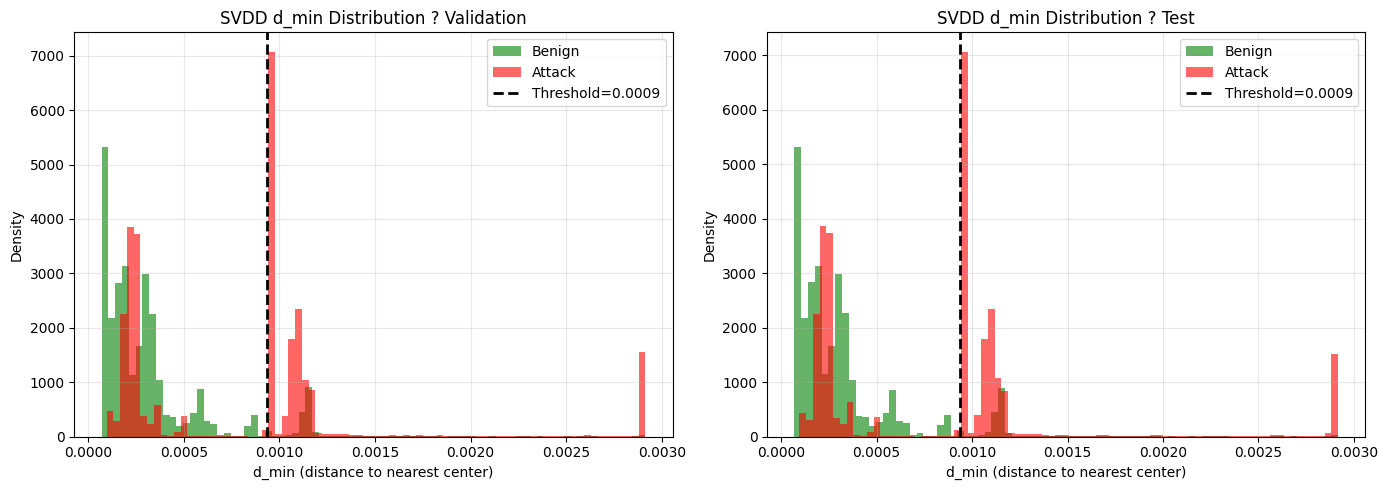

In [26]:
def evaluate(name, y_true, y_pred, y_score=None):
    print(f"\n{'='*55}")
    print(f"  {name}")
    print(f"{'='*55}")
    print(classification_report(y_true, y_pred,
                                target_names=['Benign', 'Attack'], digits=4))
    cm = confusion_matrix(y_true, y_pred)
    cm_flat = cm.ravel()
    if len(cm_flat) == 4:
        tn, fp, fn, tp = cm_flat
    else:
        tn, fp, fn, tp = (cm[0,0], 0, 0, 0) if y_pred.sum()==0 else (0, 0, 0, cm[0,0])
    print(f"  TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")
    denom_rec = tp + fn
    denom_pre = tp + fp
    recall_val    = tp / denom_rec if denom_rec > 0 else 0.0
    precision_val = tp / denom_pre if denom_pre > 0 else 0.0
    fpr_val = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    print(f"  Recall (Attack) = {recall_val:.4f}   FPR = {fpr_val:.4f}")
    if y_score is not None:
        try:
            print(f"  AUC-ROC = {roc_auc_score(y_true, y_score):.4f}")
        except Exception:
            pass
    return {'f1': f1_score(y_true, y_pred, zero_division=0),
            'recall': recall_val, 'precision': precision_val, 'fpr': fpr_val,
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp}


# Compute SVDD scores
t0 = time.time()
svdd_scores_val  = svdd.decision_scores(X_val_s)
svdd_scores_test = svdd.decision_scores(X_test_s)
svdd_time = (time.time() - t0) / (len(X_val_s) + len(X_test_s)) * 1000
print(f"SVDD inference: {svdd_time:.4f} ms/sample")

# Tune threshold tren validation set (PR-curve + F1 max)
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_c, recall_c, thresholds_c = precision_recall_curve(y_val, svdd_scores_val)
f1_curve = 2 * precision_c * recall_c / (precision_c + recall_c + 1e-9)
best_idx = f1_curve.argmax()
SVDD_THRESHOLD = thresholds_c[best_idx]
print(f"\nSVDD threshold (F1-max on val): {SVDD_THRESHOLD:.6f}")
print(f"  Val  -> F1={f1_curve[best_idx]:.4f}  Recall={recall_c[best_idx]:.4f}  Precision={precision_c[best_idx]:.4f}")
print(f"  AUC-PR (val): {average_precision_score(y_val, svdd_scores_val):.4f}")

svdd_pred_val  = (svdd_scores_val  > SVDD_THRESHOLD).astype(int)
svdd_pred_test = (svdd_scores_test > SVDD_THRESHOLD).astype(int)

res_svdd_val  = evaluate("SVDD ? Validation", y_val,  svdd_pred_val,  svdd_scores_val)
res_svdd_test = evaluate("SVDD ? Test",       y_test, svdd_pred_test, svdd_scores_test)

# Score distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, split, scores, labels in [
    (axes[0], 'Validation', svdd_scores_val, y_val),
    (axes[1], 'Test',       svdd_scores_test, y_test)
]:
    clip_p = np.percentile(scores, 99)
    sc = np.clip(scores, 0, clip_p)
    ax.hist(sc[labels==0], bins=80, alpha=0.6, color='green', label='Benign', density=True)
    ax.hist(sc[labels==1], bins=80, alpha=0.6, color='red',   label='Attack', density=True)
    ax.axvline(min(SVDD_THRESHOLD, clip_p), color='black', linestyle='--', linewidth=2,
               label=f'Threshold={SVDD_THRESHOLD:.4f}')
    ax.set_title(f'SVDD d_min Distribution ? {split}')
    ax.set_xlabel('d_min (distance to nearest center)')
    ax.set_ylabel('Density')
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('svdd_score_dist.png', dpi=150, bbox_inches='tight')
plt.show()

## CELL 10 — Train XGBoost (Binary)

In [27]:
from sklearn.metrics import average_precision_score

# -- Build SVDD-augmented features: [78 raw | K sphere distances | d_min] --
print("Computing SVDD sphere distances for XGBoost augmentation...")
svdd_dists_train = svdd.all_sphere_distances(X_xgb_train_s)   # [n, K]
svdd_dists_val    = svdd.all_sphere_distances(X_val_s)
svdd_dists_test   = svdd.all_sphere_distances(X_test_s)

SPHERE_FEATURES = [f"svdd_dist_{k}" for k in range(K_IN)]
AUGMENTED_FEATURES = FEATURES + SPHERE_FEATURES + ["svdd_dmin"]

X_xgb_train_aug = np.concatenate(
    [X_xgb_train_s, svdd_dists_train, svdd_dists_train.min(axis=1, keepdims=True)], axis=1)
X_val_aug = np.concatenate(
    [X_val_s, svdd_dists_val, svdd_dists_val.min(axis=1, keepdims=True)], axis=1)
X_test_aug = np.concatenate(
    [X_test_s, svdd_dists_test, svdd_dists_test.min(axis=1, keepdims=True)], axis=1)

print(f"Original features : {X_xgb_train_s.shape[1]}")
print(f"SVDD sphere dists : {K_IN}")
print(f"d_min             : 1")
print(f"Augmented total   : {X_xgb_train_aug.shape[1]}  <- XGBoost input")

scale_pos = int((y_xgb_train == 0).sum()) / int((y_xgb_train == 1).sum())
print(f"scale_pos_weight = {scale_pos:.2f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos,
    eval_metric='logloss',
    random_state=SEED,
    n_jobs=-1,
    tree_method='hist',
    device='cuda' if torch.cuda.is_available() else 'cpu',
    early_stopping_rounds=20
)

if os.path.exists(XGB_PATH):
    print(f"[Checkpoint] Found {XGB_PATH} - loading, skipping training...")
    xgb_model = joblib.load(XGB_PATH)
else:
    print(f"Training SVDD-Augmented XGBoost (saving to {XGB_PATH})...")
    t0 = time.time()
    xgb_model.fit(
        X_xgb_train_aug, y_xgb_train,
        eval_set=[(X_val_aug, y_val)],
        verbose=50
    )
    print(f"XGBoost training time: {time.time()-t0:.1f}s")
    joblib.dump(xgb_model, XGB_PATH)

t0 = time.time()
xgb_proba_val  = xgb_model.predict_proba(X_val_aug)[:, 1]
xgb_time = (time.time() - t0) / len(X_val_aug) * 1000
print(f"XGBoost inference: {xgb_time:.4f} ms/sample")

xgb_proba_test = xgb_model.predict_proba(X_test_aug)[:, 1]
xgb_pred_val   = (xgb_proba_val  >= 0.5).astype(int)
xgb_pred_test  = (xgb_proba_test >= 0.5).astype(int)

res_xgb_val  = evaluate("SVDD-Aug XGBoost - Validation", y_val,  xgb_pred_val,  xgb_proba_val)
res_xgb_test = evaluate("SVDD-Aug XGBoost - Test",       y_test, xgb_pred_test, xgb_proba_test)
print(f"AUC-PR (val) : {average_precision_score(y_val,  xgb_proba_val):.4f}")
print(f"AUC-PR (test): {average_precision_score(y_test, xgb_proba_test):.4f}")

Computing SVDD sphere distances for XGBoost augmentation...
Original features : 78
SVDD sphere dists : 10
d_min             : 1
Augmented total   : 89  <- XGBoost input
scale_pos_weight = 4.00
Training SVDD-Augmented XGBoost (saving to checkpoints\xgb_svdd_model_v1_infilteration.pkl)...
[0]	validation_0-logloss:0.65262
[50]	validation_0-logloss:0.11698
[100]	validation_0-logloss:0.03842
[150]	validation_0-logloss:0.01805
[199]	validation_0-logloss:0.01085
XGBoost training time: 4.3s
XGBoost inference: 0.0007 ms/sample

  SVDD-Aug XGBoost - Validation
              precision    recall  f1-score   support

      Benign     0.9996    0.9975    0.9986    243084
      Attack     0.9903    0.9985    0.9944     60771

    accuracy                         0.9977    303855
   macro avg     0.9949    0.9980    0.9965    303855
weighted avg     0.9978    0.9977    0.9977    303855

  TN=242,487  FP=597  FN=90  TP=60,681
  Recall (Attack) = 0.9985   FPR = 0.0025
  AUC-ROC = 0.9999

  SVDD-Aug XGBo

## CELL 11 — SHAP Feature Importance (XGBoost)

Computing SHAP values on augmented features (sample 5000)...


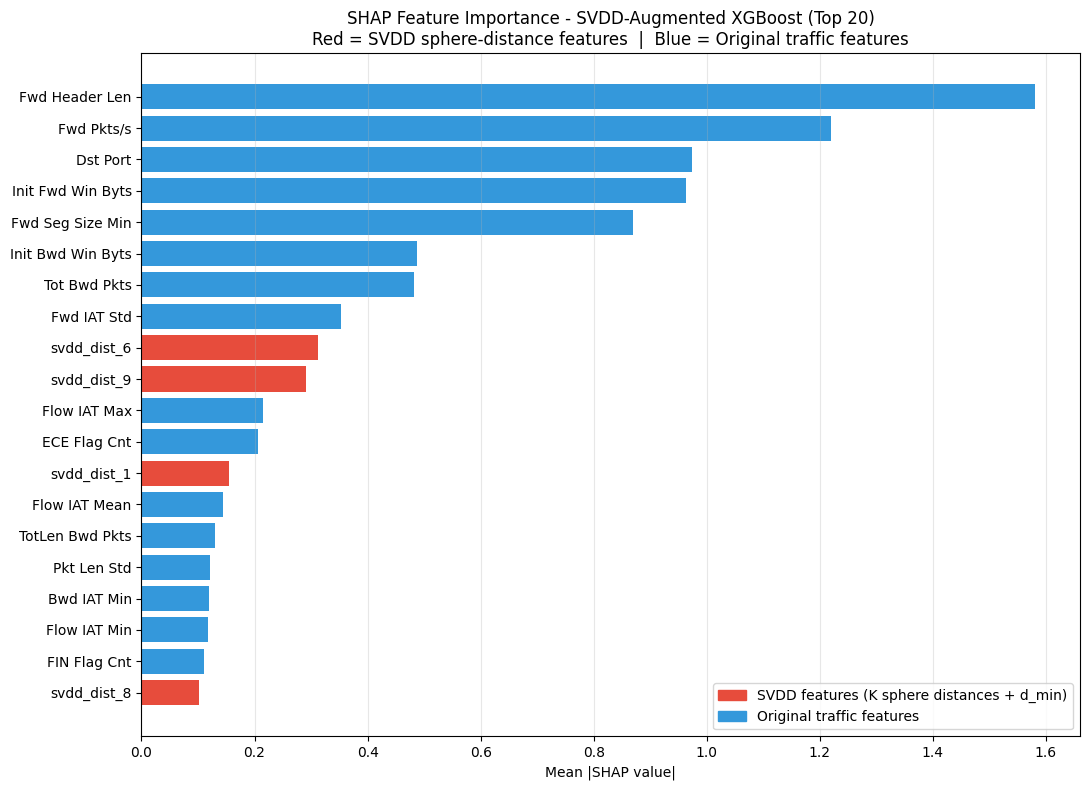

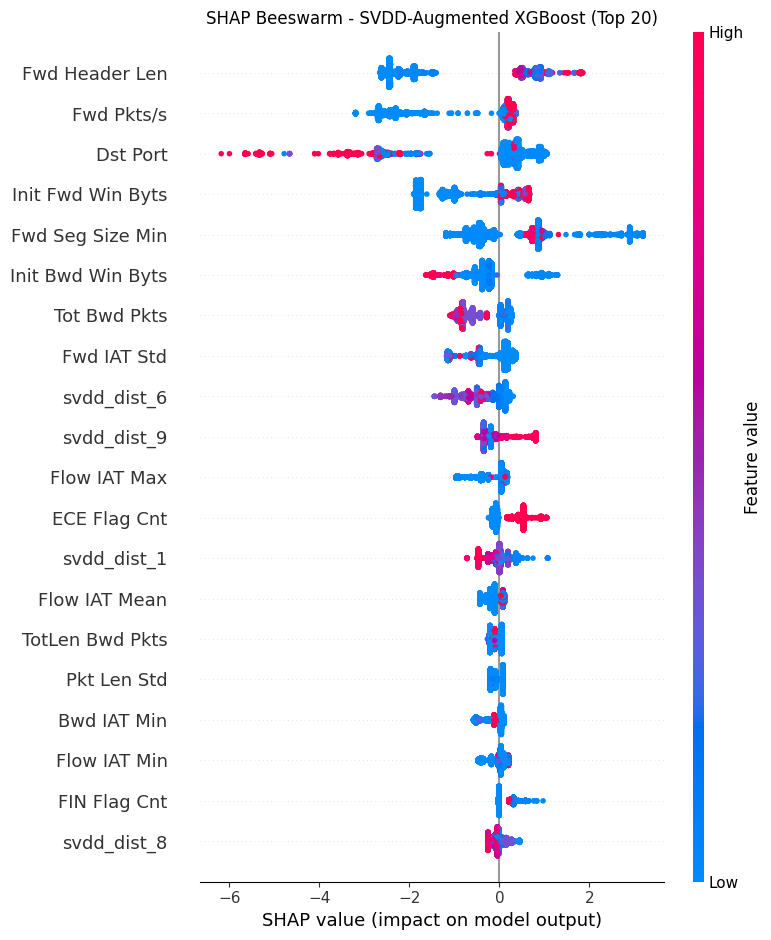


Top 20 features by SHAP:
   1. Fwd Header Len                      1.581136
   2. Fwd Pkts/s                          1.219195
   3. Dst Port                            0.973284
   4. Init Fwd Win Byts                   0.962542
   5. Fwd Seg Size Min                    0.868972
   6. Init Bwd Win Byts                   0.486547
   7. Tot Bwd Pkts                        0.481617
   8. Fwd IAT Std                         0.352250
   9. svdd_dist_6                         0.312839 <- SVDD feature
  10. svdd_dist_9                         0.290782 <- SVDD feature
  11. Flow IAT Max                        0.214523
  12. ECE Flag Cnt                        0.206236
  13. svdd_dist_1                         0.154230 <- SVDD feature
  14. Flow IAT Mean                       0.143632
  15. TotLen Bwd Pkts                     0.130944
  16. Pkt Len Std                         0.121271
  17. Bwd IAT Min                         0.118692
  18. Flow IAT Min                        0.117694
  19. FI

In [28]:
import shap

print("Computing SHAP values on augmented features (sample 5000)...")
shap_idx  = np.random.choice(len(X_val_aug), min(5000, len(X_val_aug)), replace=False)
explainer  = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_val_aug[shap_idx])

mean_abs_shap  = np.abs(shap_values).mean(axis=0)
top20_idx      = np.argsort(mean_abs_shap)[::-1][:20]
top20_features = [AUGMENTED_FEATURES[i] for i in top20_idx]

colors = ['#e74c3c' if 'svdd_' in f else '#3498db' for f in top20_features]

# Bar chart
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(range(len(top20_features)), mean_abs_shap[top20_idx][::-1],
        color=colors[::-1])
ax.set_yticks(range(len(top20_features)))
ax.set_yticklabels(top20_features[::-1], fontsize=10)
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('SHAP Feature Importance - SVDD-Augmented XGBoost (Top 20)\n'
             'Red = SVDD sphere-distance features  |  Blue = Original traffic features')
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#e74c3c', label='SVDD features (K sphere distances + d_min)'),
    Patch(color='#3498db', label='Original traffic features')
], loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'shap_svdd_bar.png'), dpi=150, bbox_inches='tight')
plt.show()

# Beeswarm
plt.figure(figsize=(11, 8))
shap.summary_plot(shap_values[:, top20_idx],
                  pd.DataFrame(X_val_aug[shap_idx][:, top20_idx], columns=top20_features),
                  show=False)
plt.title('SHAP Beeswarm - SVDD-Augmented XGBoost (Top 20)')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'shap_svdd_beeswarm.png'), dpi=150, bbox_inches='tight')
plt.show()

print("\nTop 20 features by SHAP:")
for i, (feat, val) in enumerate(zip(top20_features, mean_abs_shap[top20_idx])):
    tag = ' <- SVDD feature' if 'svdd_' in feat else ''
    print(f"  {i+1:2d}. {feat:<35} {val:.6f}{tag}")

svdd_feat_idx = [i for i, f in enumerate(AUGMENTED_FEATURES) if 'svdd_' in f]
org_feat_idx  = [i for i, f in enumerate(AUGMENTED_FEATURES) if 'svdd_' not in f]
svdd_contrib  = mean_abs_shap[svdd_feat_idx].sum()
org_contrib   = mean_abs_shap[org_feat_idx].sum()
total         = svdd_contrib + org_contrib
print(f"\nSVDD features contribution     : {svdd_contrib/total*100:.1f}%")
print(f"Original features contribution : {org_contrib/total*100:.1f}%")

## CELL 12 — Final Evaluation & Zero-shot Test

In [29]:
from sklearn.metrics import average_precision_score

# Zero-shot evaluation (Infilteration) — SVDD-Augmented XGBoost only, no OR-Fusion
svdd_dists_zero = svdd.all_sphere_distances(X_zeroshot_s)
X_zeroshot_aug = np.concatenate(
    [X_zeroshot_s, svdd_dists_zero, svdd_dists_zero.min(axis=1, keepdims=True)], axis=1)

xgb_proba_zero = xgb_model.predict_proba(X_zeroshot_aug)[:, 1]
xgb_pred_zero  = (xgb_proba_zero >= 0.5).astype(int)
svdd_pred_zero = (svdd_dists_zero.min(axis=1) > SVDD_THRESHOLD).astype(int)

zero_total = len(y_zeroshot)
print(f"\n{'='*60}")
print(f"  ZERO-SHOT — Infilteration ({zero_total:,} samples, all attack)")
print(f"{'='*60}")
for name, pred in [("SVDD only", svdd_pred_zero),
                   ("SVDD-Aug XGBoost", xgb_pred_zero)]:
    detected = pred.sum()
    print(f"  {name:<20} Detection Rate = {detected/zero_total*100:.2f}%  ({detected:,}/{zero_total:,})")

# Summary table
print("\n" + "="*70)
print("  SUMMARY — Test Set (binary_split_dataset_z_Infilteration)")
print("="*70)
print(f"{'Method':<28} {'F1':>8} {'Recall':>8} {'Precision':>10} {'AUC-ROC':>9}")
print("-"*70)
for name, res, score in [
    ("SVDD only",        res_svdd_test, svdd_scores_test),
    ("SVDD-Aug XGBoost", res_xgb_test,  xgb_proba_test),
]:
    auc = roc_auc_score(y_test, score)
    print(f"{name:<28} {res['f1']:>8.4f} {res['recall']:>8.4f} {res['precision']:>10.4f} {auc:>9.4f}")
print("="*70)

print("\n  AUC-PR (Precision-Recall, better for imbalanced data):")
for name, score in [("SVDD only", svdd_scores_test),
                    ("SVDD-Aug XGBoost", xgb_proba_test)]:
    ap = average_precision_score(y_test, score)
    print(f"  {name:<25} {ap:.4f}")


  ZERO-SHOT — Infilteration (161,934 samples, all attack)
  SVDD only            Detection Rate = 28.08%  (45,465/161,934)
  SVDD-Aug XGBoost     Detection Rate = 1.05%  (1,704/161,934)

  SUMMARY — Test Set (binary_split_dataset_z_Infilteration)
Method                             F1   Recall  Precision   AUC-ROC
----------------------------------------------------------------------
SVDD only                      0.6237   0.5671     0.6929    0.7554
SVDD-Aug XGBoost               0.9948   0.9984     0.9911    0.9999

  AUC-PR (Precision-Recall, better for imbalanced data):
  SVDD only                 0.4724
  SVDD-Aug XGBoost          0.9996


## CELL 14 — Inference Speed Benchmark (Real-time Feasibility)

In [32]:
BATCH_SIZE_BENCH = 1000
X_bench = X_test_s[:BATCH_SIZE_BENCH]

_ = svdd.decision_scores(X_bench)  # warm-up

N_RUNS = 20
svdd_times, xgb_times, total_times = [], [], []

for _ in range(N_RUNS):
    t0 = time.time(); svdd.all_sphere_distances(X_bench); svdd_times.append(time.time()-t0)

    t0 = time.time()
    d = svdd.all_sphere_distances(X_bench)
    X_bench_aug = np.concatenate([X_bench, d, d.min(axis=1, keepdims=True)], axis=1)
    xgb_model.predict_proba(X_bench_aug)
    xgb_times.append(time.time()-t0)

    t0 = time.time()
    d = svdd.all_sphere_distances(X_bench)
    X_bench_aug = np.concatenate([X_bench, d, d.min(axis=1, keepdims=True)], axis=1)
    p = xgb_model.predict_proba(X_bench_aug)[:, 1]
    _ = (p > 0.7).astype(int)  # single XGBoost threshold - no separate SVDD branch
    total_times.append(time.time()-t0)

print(f"Batch size: {BATCH_SIZE_BENCH} flows")
print(f"{'Component':<20} {'Mean (ms)':>12} {'Std (ms)':>10} {'Max (ms)':>10}")
print("-"*55)
for name, times in [("SVDD encode", svdd_times), ("XGBoost (incl. SVDD)", xgb_times), ("Total Pipeline", total_times)]:
    t_ms = np.array(times) * 1000
    print(f"{name:<20} {t_ms.mean():>12.2f} {t_ms.std():>10.2f} {t_ms.max():>10.2f}")
print(f"\n-> TShark cycle = 10,000ms  |  Pipeline latency = {np.mean(total_times)*1000:.1f}ms")
print(f"-> Headroom = {10000 - np.mean(total_times)*1000:.0f}ms")

Batch size: 1000 flows
Component               Mean (ms)   Std (ms)   Max (ms)
-------------------------------------------------------
SVDD encode                 91.07      51.96     249.20
XGBoost (incl. SVDD)        67.95       4.37      79.74
Total Pipeline              89.06      37.76     253.23

-> TShark cycle = 10,000ms  |  Pipeline latency = 89.1ms
-> Headroom = 9911ms


## CELL 15 — Confusion Matrix Visualization

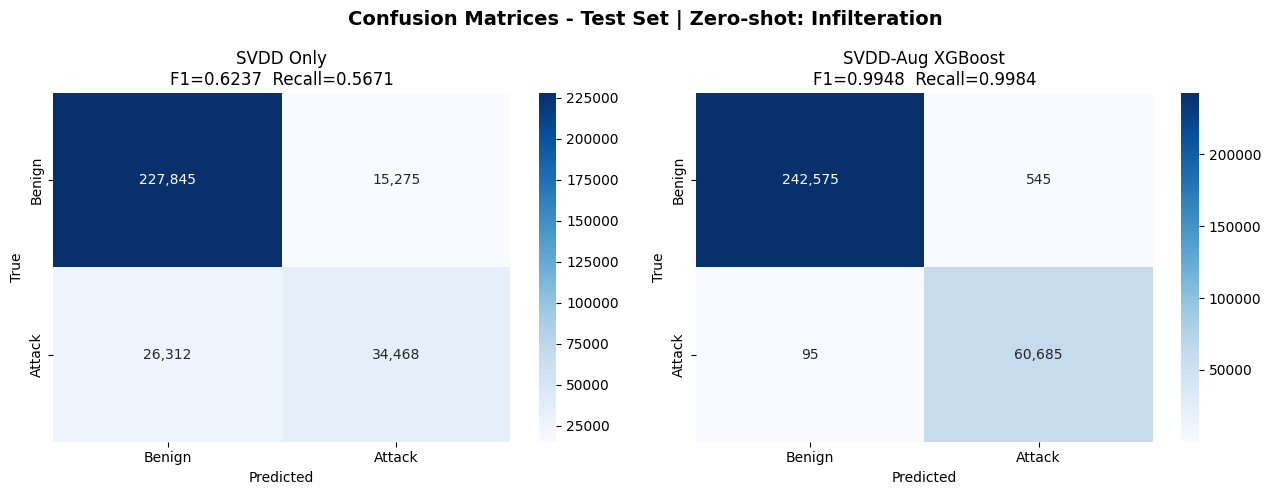

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
models_cm = [
    ("SVDD Only",         svdd_pred_test),
    ("SVDD-Aug XGBoost",  xgb_pred_test),
]
for ax, (name, pred) in zip(axes, models_cm):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax,
                xticklabels=['Benign', 'Attack'],
                yticklabels=['Benign', 'Attack'])
    f1_val  = f1_score(y_test, pred, zero_division=0)
    rec_val = recall_score(y_test, pred, zero_division=0)
    ax.set_title(f'{name}\nF1={f1_val:.4f}  Recall={rec_val:.4f}')
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')

plt.suptitle(f'Confusion Matrices - Test Set | Zero-shot: {ZEROSHOT_LABEL}',
             fontsize=14, fontweight='bold')
plt.tight_layout()
cm_path = os.path.join(IMAGES_DIR, f'confusion_matrices_svdd{ARTIFACT_SUFFIX}.png')
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()